In [1]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation, NMF

from gensim.corpora import Dictionary
from gensim.models import CoherenceModel

from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from umap import UMAP

import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from scipy.optimize import linear_sum_assignment
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [2]:
CURRENT_YEAR = 2026
LAST_COMPLETE_YEAR = 2025
RANDOM_STATE = 42

### Load and preprocess data

In [3]:
citation_df = pd.read_csv("../data/master_dataset.csv")

# Map journals
journal_map = {
    "financial services review": "FSR",
    "financial planning review": "FPR",
    "journal of financial counseling and planning": "JFCP",
}

citation_df["journal"] = (
    citation_df["source_title"].str.strip().str.lower().map(journal_map)
)

# Article age (papers from the current year are given age 1)
citation_df['year_since_pub'] = CURRENT_YEAR - citation_df['year']
citation_df['year_since_pub'] = citation_df['year_since_pub'].replace(0, 1)

# Combined text per paper: title + abstract + author keywords
citation_df["combined_text"] = (
    citation_df["title"].fillna("") + " " +
    citation_df["abstract"].fillna("") + " " +
    citation_df["author_keywords"].fillna("").str.replace(";", " ")
)

In [4]:
custom_stopwords = {
    "study", "results", "paper", "research", "article",
    "using", "based", "data", "analysis", "findings",
    "significant", "significantly",
    "academy", "service", "services",
    "right", "rights", "reserved"
}

stop_words = set(ENGLISH_STOP_WORDS).union(custom_stopwords)

# Lemmatize and clean combined text
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    """Lowercase, strip punctuation/numbers, remove stopwords, lemmatise."""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words]
    return " ".join(tokens)

citation_df["cleaned_text"] = citation_df["combined_text"].apply(clean_text)

### Vectorisation

In [5]:
# Drop terms in more than 85% of documents or fewer than 5
count_vectorizer = CountVectorizer(max_df=0.85, min_df=5, ngram_range=(1, 3))
count_matrix = count_vectorizer.fit_transform(citation_df["cleaned_text"])

tfidf_vectorizer = TfidfVectorizer(max_df=0.85, min_df=5, ngram_range=(1, 3))
tfidf_matrix = tfidf_vectorizer.fit_transform(citation_df["cleaned_text"])

### Coherence setup

In [6]:
coherence_texts = [doc.split() for doc in citation_df["cleaned_text"]]
gensim_dictionary = Dictionary(coherence_texts)

def get_topic_words(model, vectorizer, n_top_words=10, unigram_only=False):
    """Top N words per topic."""
    feature_names = vectorizer.get_feature_names_out()
    is_unigram = np.array([" " not in f for f in feature_names])
    topics = []
    for weights in model.components_:
        order = weights.argsort()[::-1]
        if unigram_only:
            order = order[is_unigram[order]]
        topics.append([feature_names[i] for i in order[:n_top_words]])
    return topics

def coherence_score(topics):
    """C_v coherence; drops words missing from the dictionary."""
    vocab = gensim_dictionary.token2id
    topics = [[w for w in t if w in vocab] for t in topics]
    topics = [t for t in topics if len(t) >= 2]
    if not topics:
        return np.nan
    return CoherenceModel(
        topics=topics, texts=coherence_texts, dictionary=gensim_dictionary,
        coherence="c_v", processes=1,
    ).get_coherence()

### LDA and NMF

In [7]:
k_values = range(4, 20)

lda_results = {}
for k in k_values:
    lda_model = LatentDirichletAllocation(
        n_components=k, random_state=RANDOM_STATE, learning_method="batch", max_iter=50
    ).fit(count_matrix)
    lda_results[k] = {
        "model": lda_model,
        "coherence": coherence_score(get_topic_words(lda_model, count_vectorizer, 10, unigram_only=True)),
        "perplexity": lda_model.perplexity(count_matrix),
    }

In [8]:
nmf_results = {}
for k in k_values:
    nmf_model = NMF(n_components=k, random_state=RANDOM_STATE, init="nndsvda", max_iter=500).fit(tfidf_matrix)
    nmf_results[k] = {
        "model": nmf_model,
        "coherence": coherence_score(get_topic_words(nmf_model, tfidf_vectorizer, 10, unigram_only=True)),
    }

In [9]:
k_selection_df = pd.DataFrame({
    "k": list(k_values),
    "lda_coherence": [lda_results[k]["coherence"] for k in k_values],
    "lda_perplexity": [lda_results[k]["perplexity"] for k in k_values],
    "nmf_coherence": [nmf_results[k]["coherence"] for k in k_values],
})

k_selection_df

,k,lda_coherence,lda_perplexity,nmf_coherence
0,4,0.578637,1306.776418,0.690823
1,5,0.537891,1308.942955,0.687684
2,6,0.608224,1251.688236,0.645720
3,7,0.598082,1250.339560,0.624395
4,8,0.637079,1236.268220,0.620618
5,9,0.615989,1205.342625,0.616120
6,10,0.603155,1187.205917,0.614697
7,11,0.570751,1182.549979,0.615412
8,12,0.549431,1186.972471,0.602179
9,13,0.533986,1183.598006,0.615214


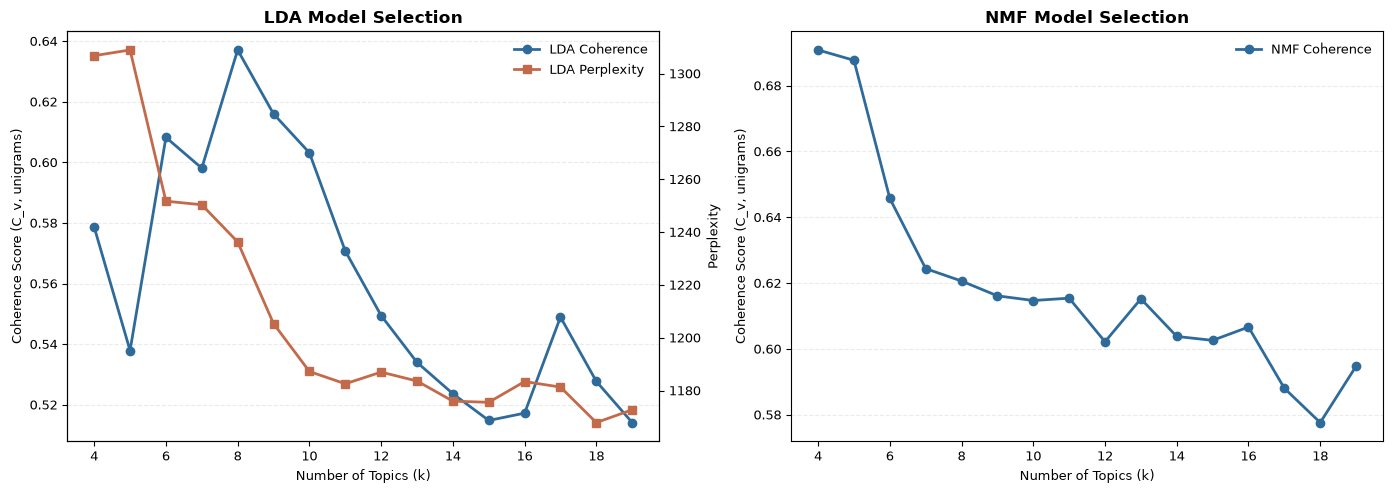

In [10]:
coherence_colour = "#2F6B9A"
perplexity_colour = "#C26A4A"

plt.rcParams.update({
    "font.size": 9, "axes.labelsize": 9, "axes.titlesize": 12,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "legend.frameon": False,
})

fig, (ax_lda, ax_nmf) = plt.subplots(1, 2, figsize=(14, 5))

ax_lda.plot(k_selection_df["k"], k_selection_df["lda_coherence"],
            label="LDA Coherence", color=coherence_colour, marker="o", linewidth=2)
ax_lda.set_xlabel("Number of Topics (k)")
ax_lda.set_ylabel("Coherence Score (C_v, unigrams)")
ax_lda.set_title("LDA Model Selection", fontweight="bold")
ax_lda.grid(axis="y", linestyle="--", alpha=0.25)

ax_lda_2 = ax_lda.twinx()
ax_lda_2.plot(k_selection_df["k"], k_selection_df["lda_perplexity"],
              label="LDA Perplexity", color=perplexity_colour, marker="s", linewidth=2)
ax_lda_2.set_ylabel("Perplexity")

lines_1, labels_1 = ax_lda.get_legend_handles_labels()
lines_2, labels_2 = ax_lda_2.get_legend_handles_labels()
ax_lda.legend(lines_1 + lines_2, labels_1 + labels_2, loc="best", frameon=False)

ax_nmf.plot(k_selection_df["k"], k_selection_df["nmf_coherence"],
            label="NMF Coherence", color=coherence_colour, marker="o", linewidth=2)
ax_nmf.set_xlabel("Number of Topics (k)")
ax_nmf.set_ylabel("Coherence Score (C_v, unigrams)")
ax_nmf.set_title("NMF Model Selection", fontweight="bold")
ax_nmf.grid(axis="y", linestyle="--", alpha=0.25)
ax_nmf.legend(loc="best", frameon=False)

plt.tight_layout()
plt.savefig("lda_nmf_model_selection.png", dpi=300, bbox_inches="tight")
plt.show()

In [11]:
lda_candidates = [6, 8, 9, 10]
nmf_candidates = [5, 9, 10, 11, 13]

for k in lda_candidates:
    for i, topic in enumerate(get_topic_words(lda_results[k]["model"], count_vectorizer, 10)):
        print(f"LDA k={k}, Topic {i}: {', '.join(topic)}")

for k in nmf_candidates:
    for i, topic in enumerate(get_topic_words(nmf_results[k]["model"], tfidf_vectorizer, 10)):
        print(f"NMF k={k}, Topic {i}: {', '.join(topic)}")

LDA k=6, Topic 0: fund, investor, market, stock, investment, return, portfolio, performance, mutual, mutual fund
LDA k=6, Topic 1: risk, planning, financial planning, planner, financial planner, tolerance, risk tolerance, advice, advisor, investment
LDA k=6, Topic 2: retirement, tax, asset, rate, saving, portfolio, plan, allocation, risk, income
LDA k=6, Topic 3: education, knowledge, literacy, behavior, financial literacy, planning, financial knowledge, association, financial education, counseling
LDA k=6, Topic 4: satisfaction, counseling, management, financial counseling, association, behavior, relationship, association financial, family, stress
LDA k=6, Topic 5: household, credit, saving, consumer, income, education, survey, debt, finance, student
LDA k=8, Topic 0: fund, investor, market, performance, return, mutual, mutual fund, investment, index, equity
LDA k=8, Topic 1: planning, financial planning, planner, financial planner, advisor, advice, insurance, life, client, financial 

### BERTopic comparison

In [12]:
embedding_model = SentenceTransformer('all-MiniLM-L6-v2')

# Embeddings from raw text keep semantic context
raw_docs = citation_df["combined_text"].tolist()
embeddings = embedding_model.encode(raw_docs, show_progress_bar=False)

clean_docs = citation_df["cleaned_text"].tolist()

bertopic_search_results = []
bertopic_models = {}

for size in range(10, 31):

    bertopic_vectorizer = CountVectorizer(ngram_range=(1, 3))

    umap_model = UMAP(
        n_neighbors=10, n_components=5, min_dist=0.0,
        metric="cosine", random_state=RANDOM_STATE,
    )

    candidate_model = BERTopic(
        vectorizer_model=bertopic_vectorizer,
        embedding_model=embedding_model,
        umap_model=umap_model,
        min_topic_size=size,
        top_n_words=30,
        calculate_probabilities=True,
        verbose=False,
    )
    
    candidate_topics, candidate_probs = candidate_model.fit_transform(clean_docs, embeddings)

    # Number of real topics, excluding the outlier topic (-1)
    n_topics = len(set(candidate_topics)) - (1 if -1 in candidate_topics else 0)

    # Documents HDBSCAN could not assign to any topic
    n_outliers = sum(t == -1 for t in candidate_topics)
    outlier_ratio = n_outliers / len(candidate_topics) * 100

    # Topic sizes (documents per topic), excluding outliers
    topic_info = candidate_model.get_topic_info()
    topic_sizes = topic_info[topic_info.Topic != -1]["Count"]
    size_std = topic_sizes.std() if not topic_sizes.empty else 0

    # Top 10 unigram words per topic for coherence
    topic_word_lists = [
        [w for w, _ in candidate_model.get_topic(t) if " " not in w][:10]
        for t in sorted(set(candidate_topics)) if t != -1
    ]

    coherence = coherence_score(topic_word_lists)

    bertopic_search_results.append({
        "min_topic_size": size, "n_topics": n_topics,
        "n_outliers": n_outliers, "outlier_ratio": outlier_ratio,
        "topic_size_std": size_std, "coherence": coherence,
    })

    bertopic_models[size] = {
        "model": candidate_model, "topics": candidate_topics,
        "probabilities": candidate_probs,
    }

    print(
        f"BERTopic: min_topic_size={size}, n_topics={n_topics}, "
        f"outlier_ratio={outlier_ratio:.2f}%, topic_size_std={size_std:.4f}, "
        f"coherence={coherence:.4f}"
    )

bertopic_results_df = pd.DataFrame(bertopic_search_results)
bertopic_results_df.to_csv("bertopic_search_results.csv", index=False)

BERTopic: min_topic_size=10, n_topics=32, outlier_ratio=30.84%, topic_size_std=18.5280, coherence=0.5475
BERTopic: min_topic_size=11, n_topics=27, outlier_ratio=31.50%, topic_size_std=19.3834, coherence=0.5396
BERTopic: min_topic_size=12, n_topics=27, outlier_ratio=34.14%, topic_size_std=17.8634, coherence=0.5431
BERTopic: min_topic_size=13, n_topics=24, outlier_ratio=34.21%, topic_size_std=19.3001, coherence=0.5426
BERTopic: min_topic_size=14, n_topics=23, outlier_ratio=34.95%, topic_size_std=18.1155, coherence=0.5490
BERTopic: min_topic_size=15, n_topics=24, outlier_ratio=36.42%, topic_size_std=17.7297, coherence=0.5505
BERTopic: min_topic_size=16, n_topics=19, outlier_ratio=29.30%, topic_size_std=69.6149, coherence=0.5172
BERTopic: min_topic_size=17, n_topics=18, outlier_ratio=29.66%, topic_size_std=71.4090, coherence=0.5198
BERTopic: min_topic_size=18, n_topics=20, outlier_ratio=37.67%, topic_size_std=25.3200, coherence=0.5294
BERTopic: min_topic_size=19, n_topics=15, outlier_ratio

In [13]:
for size in [15, 20, 21, 24, 26]:
    model = bertopic_models[size]["model"]
    topic_info = model.get_topic_info()
    for topic_id in topic_info["Topic"]:
        if topic_id == -1:
            continue
        words = [w for w, _ in model.get_topic(topic_id)[:10]]
        count = topic_info.loc[topic_info["Topic"] == topic_id, "Count"].iloc[0]
        print(f"BERTopic min_topic_size={size}, Topic {topic_id} (n={count}): " + ", ".join(words))

BERTopic min_topic_size=15, Topic 0 (n=90): financial, literacy, financial literacy, education, knowledge, financial education, student, financial knowledge, finance, personal finance
BERTopic min_topic_size=15, Topic 1 (n=68): portfolio, retirement, asset, allocation, withdrawal, asset allocation, risk, rate, model, strategy
BERTopic min_topic_size=15, Topic 2 (n=63): financial, socialization, financial socialization, parent, behavior, adult, family, young, financial behavior, young adult
BERTopic min_topic_size=15, Topic 3 (n=58): fund, mutual, mutual fund, performance, investor, return, expense, fund performance, expense ratio, mutual fund performance
BERTopic min_topic_size=15, Topic 4 (n=47): risk, tolerance, risk tolerance, financial risk, financial risk tolerance, financial, measure, assessment, investment, aversion
BERTopic min_topic_size=15, Topic 5 (n=40): stock, market, investor, individual investor, dividend, return, individual, earnings, forecast, trading
BERTopic min_topi

### Final Model

In [14]:
FINAL_NMF_K = 11
final_model = nmf_results[FINAL_NMF_K]["model"]
topic_weights = final_model.transform(tfidf_matrix)

row_sums = topic_weights.sum(axis=1, keepdims=True)
zero_rows = row_sums.ravel() == 0
print(f"Documents with no NMF topic weight: {zero_rows.sum()}")

topic_proportions = np.divide(
    topic_weights, row_sums,
    out=np.full_like(topic_weights, np.nan),
    where=row_sums > 0,
)

nmf_topic_cols = [f"nmf_topic_{i}" for i in range(FINAL_NMF_K)]
citation_df[nmf_topic_cols] = topic_proportions

# Dominant topic; -1 for documents with no topic weight
citation_df["nmf_topic"] = np.where(zero_rows, -1, topic_weights.argmax(axis=1))

Documents with no NMF topic weight: 0


In [15]:
topic_labels = {
    0: "Retirement Planning",
    1: "Mutual Funds",
    2: "Financial Literacy",
    3: "Risk Tolerance",
    4: "Credit Card Debt",
    5: "Portfolio Investment",
    6: "Household Finance",
    7: "Financial Planning and Advice",
    8: "Student Finance",
    9: "Financial Behaviour and Wellbeing",
    10: "Tax and Retirement Accounts",
}

for i, words in enumerate(get_topic_words(final_model, tfidf_vectorizer, 8)):
    print(f"{i:>2} {topic_labels[i]:<35} {', '.join(words)}")

citation_df["topic_label"] = citation_df["nmf_topic"].map(topic_labels)

def topic_label(col):
    return topic_labels[int(col.split("_")[-1])]

 0 Retirement Planning                 retirement, saving, retirement saving, plan, retirement planning, age, social security, pension
 1 Mutual Funds                        fund, mutual, mutual fund, performance, return, investor, fund performance, expense
 2 Financial Literacy                  literacy, financial literacy, knowledge, financial education, education, financial knowledge, program, education financial
 3 Risk Tolerance                      risk, tolerance, risk tolerance, financial risk, financial risk tolerance, measure, investment, aversion
 4 Credit Card Debt                    credit, card, credit card, debt, consumer, credit card debt, card debt, payment
 5 Portfolio Investment                portfolio, stock, investor, market, asset, investment, allocation, return
 6 Household Finance                   household, consumer, survey consumer finance, survey consumer, consumer finance, income, finance, insurance
 7 Financial Planning and Advice       financial planning

### Topic stability

In [16]:
N_STABILITY_RUNS = 10
SUBSAMPLE_FRAC = 0.8
STABILITY_THRESHOLD = 0.5
n_docs = tfidf_matrix.shape[0]

def stability_runs(k):
    """Jaccard similarity of each topic's top 10 words to its matched topic in NMF refits on 80% subsamples."""
    base_sets = [set(t) for t in get_topic_words(nmf_results[k]["model"], tfidf_vectorizer, 10)]
    rng = np.random.default_rng(RANDOM_STATE)
    runs = []
    for _ in range(N_STABILITY_RUNS):
        idx = rng.choice(n_docs, int(SUBSAMPLE_FRAC * n_docs), replace=False)
        sub_model = NMF(n_components=k, init="nndsvda", random_state=RANDOM_STATE, max_iter=500).fit(tfidf_matrix[idx])
        sub_sets = [set(t) for t in get_topic_words(sub_model, tfidf_vectorizer, 10)]
        jaccard = np.array([[len(a & b) / len(a | b) for b in sub_sets] for a in base_sets])
        # match topics one-to-one (Hungarian algorithm)
        rows, cols = linear_sum_assignment(-jaccard)
        matched = np.empty(k)
        matched[rows] = jaccard[rows, cols]
        runs.append(matched)
    return np.array(runs)

runs = stability_runs(FINAL_NMF_K)
stability_df = pd.DataFrame({
    "topic": [topic_labels[i] for i in range(FINAL_NMF_K)],
    "mean_jaccard": runs.mean(axis=0),
    "min_jaccard": runs.min(axis=0),
    "max_jaccard": runs.max(axis=0),
})
stability_df["stable"] = stability_df["mean_jaccard"] >= STABILITY_THRESHOLD
stability_df = stability_df.sort_values("mean_jaccard", ascending=False)

print(f"Topic stability across {N_STABILITY_RUNS} subsamples ({SUBSAMPLE_FRAC:.0%} of documents):")
print(stability_df.round(2).to_string(index=False))
print(f"\nOverall mean Jaccard: {runs.mean():.2f}")
stability_df.to_csv("topic_stability.csv", index=False)

Topic stability across 10 subsamples (80% of documents):
                            topic  mean_jaccard  min_jaccard  max_jaccard  stable
             Portfolio Investment          0.88         0.67         1.00    True
    Financial Planning and Advice          0.82         0.67         1.00    True
                   Risk Tolerance          0.82         0.67         1.00    True
                 Credit Card Debt          0.80         0.43         1.00    True
                     Mutual Funds          0.79         0.54         1.00    True
                Household Finance          0.73         0.67         1.00    True
               Financial Literacy          0.72         0.43         1.00    True
                  Student Finance          0.71         0.00         1.00    True
Financial Behaviour and Wellbeing          0.70         0.54         0.82    True
              Retirement Planning          0.65         0.54         0.82    True
      Tax and Retirement Accounts        

In [17]:
for k in [10, 11, 12]:
    r = stability_runs(k)
    print(f"k={k}: mean Jaccard = {r.mean():.2f}, stable topics = {(r.mean(axis=0) >= STABILITY_THRESHOLD).sum()}/{k}")

k=10: mean Jaccard = 0.73, stable topics = 10/10
k=11: mean Jaccard = 0.72, stable topics = 10/11
k=12: mean Jaccard = 0.64, stable topics = 10/12


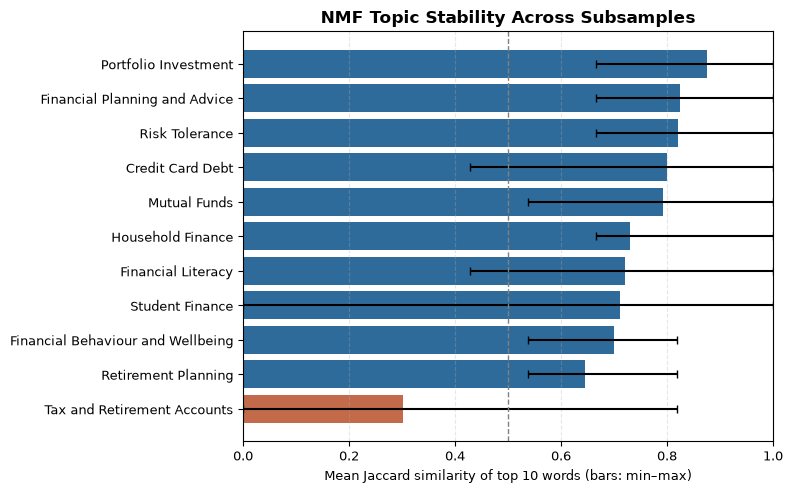

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_stab = stability_df.sort_values("mean_jaccard")
y_pos = np.arange(len(plot_stab))

ax.barh(
    y_pos, plot_stab["mean_jaccard"],
    xerr=[plot_stab["mean_jaccard"] - plot_stab["min_jaccard"],
          plot_stab["max_jaccard"] - plot_stab["mean_jaccard"]],
    color=np.where(plot_stab["stable"], "#2F6B9A", "#C26A4A"),
    capsize=3,
)
ax.axvline(STABILITY_THRESHOLD, color="grey", linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_stab["topic"])
ax.set_xlim(0, 1)
ax.set_xlabel("Mean Jaccard similarity of top 10 words (bars: min–max)")
ax.set_title("NMF Topic Stability Across Subsamples", fontweight="bold")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("topic_stability.png", dpi=300, bbox_inches="tight")
plt.show()

### Multicollinearity checks

In [19]:
topic_corr = citation_df[nmf_topic_cols].corr()
off_diag = topic_corr.where(~np.eye(len(topic_corr), dtype=bool)).abs().stack()
pair = off_diag.idxmax()
print(f"Largest |r| between topic proportions: {off_diag.max():.2f} ({topic_label(pair[0])} and {topic_label(pair[1])})")

Largest |r| between topic proportions: 0.30 (Portfolio Investment and Financial Behaviour and Wellbeing)


In [20]:
# Topic 0 (Retirement Planning) is the reference
REFERENCE_TOPIC = "nmf_topic_0"
regression_topic_cols = [c for c in nmf_topic_cols if c != REFERENCE_TOPIC]

model_df = citation_df.dropna(subset=nmf_topic_cols).copy()

X = model_df[regression_topic_cols].copy()
X["age_log"] = np.log1p(model_df["year_since_pub"])
X = pd.get_dummies(
    X.join(model_df["journal"]), columns=["journal"], drop_first=True
).astype(float)
X = sm.add_constant(X)

y = model_df["cited_by"]

In [21]:
# VIF above 5 flags multicollinearity, above 10 is severe
vif_df = pd.DataFrame({
    "variable": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])],
})
vif_df = vif_df[vif_df["variable"] != "const"].sort_values("VIF", ascending=False)
vif_df["label"] = vif_df["variable"].map(lambda v: topic_label(v) if v.startswith("nmf_topic_") else v)
print("Variance Inflation Factors:")
print(vif_df[["variable", "label", "VIF"]].to_string(index=False))

Variance Inflation Factors:
    variable                             label      VIF
journal_JFCP                      journal_JFCP 5.854280
 journal_FSR                       journal_FSR 5.206055
 nmf_topic_9 Financial Behaviour and Wellbeing 3.663896
 nmf_topic_5              Portfolio Investment 3.259971
 nmf_topic_6                 Household Finance 3.003552
 nmf_topic_7     Financial Planning and Advice 2.980203
 nmf_topic_1                      Mutual Funds 2.404213
nmf_topic_10       Tax and Retirement Accounts 2.285888
 nmf_topic_8                   Student Finance 2.151936
 nmf_topic_2                Financial Literacy 2.131949
 nmf_topic_3                    Risk Tolerance 2.071845
 nmf_topic_4                  Credit Card Debt 1.607024
     age_log                           age_log 1.464752


### Negative Binomial regression

In [22]:
nb_model = sm.NegativeBinomial(y, X)
nb_result = nb_model.fit(maxiter=200, disp=False)
print(nb_result.summary())

                     NegativeBinomial Regression Results                      
Dep. Variable:               cited_by   No. Observations:                 1362
Model:               NegativeBinomial   Df Residuals:                     1348
Method:                           MLE   Df Model:                           13
Date:                Sat, 24 Oct 2026   Pseudo R-squ.:                 0.08452
Time:                        19:08:32   Log-Likelihood:                -4710.4
converged:                       True   LL-Null:                       -5145.3
Covariance Type:            nonrobust   LLR p-value:                1.542e-177
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.6464      0.261     -2.476      0.013      -1.158      -0.135
nmf_topic_1     -0.1619      0.262     -0.619      0.536      -0.675       0.351
nmf_topic_2      2.2564      0.280      8.05

In [23]:
def fmt_p(p):
    """Format p-values for reporting."""
    return "<0.001" if p < 0.001 else f"{p:.3f}"

params = nb_result.params.drop("alpha")
conf = nb_result.conf_int().drop("alpha")
pvals = nb_result.pvalues.drop("alpha")

# Convert log coefficients to incidence rate ratios
irr_table = pd.DataFrame({
    "term": params.index,
    "IRR": np.exp(params).values,
    "CI_lower": np.exp(conf[0]).values,
    "CI_upper": np.exp(conf[1]).values,
    "p_value": pvals.values,
})


def label_row(name):
    if name.startswith("nmf_topic_"):
        return topic_label(name)
    if name == "age_log":
        return "Article age (log)"
    if name.startswith("journal_"):
        return name.replace("journal_", "Journal: ")
    if name == "const":
        return "Intercept"
    return name


irr_table["label"] = irr_table["term"].map(label_row)

# Rescale topic IRRs to a 10 pp shift from Retirement Planning (IRR ** 0.1).
is_topic = irr_table["term"].str.startswith("nmf_topic_")
irr_table["scale"] = np.where(is_topic, "per 10 pp vs Retirement Planning", "per unit")
for col in ["IRR", "CI_lower", "CI_upper"]:
    irr_table.loc[is_topic, col] = irr_table.loc[is_topic, col] ** 0.1

irr_final = irr_table[irr_table["term"] != "const"].copy()
irr_final["95% CI"] = (
    "[" + irr_final["CI_lower"].round(3).astype(str)
    + ", " + irr_final["CI_upper"].round(3).astype(str) + "]"
)
irr_final["IRR"] = irr_final["IRR"].round(3)
irr_final["p"] = irr_final["p_value"].map(fmt_p)
irr_final = irr_final[["label", "scale", "IRR", "95% CI", "p"]]

print(irr_final.to_string(index=False))
irr_final.to_csv("irr_results.csv", index=False)

                            label                            scale   IRR         95% CI      p
                     Mutual Funds per 10 pp vs Retirement Planning 0.984 [0.935, 1.036]  0.536
               Financial Literacy per 10 pp vs Retirement Planning 1.253 [1.186, 1.324] <0.001
                   Risk Tolerance per 10 pp vs Retirement Planning 1.206 [1.143, 1.273] <0.001
                 Credit Card Debt per 10 pp vs Retirement Planning 1.060 [0.998, 1.125]  0.056
             Portfolio Investment per 10 pp vs Retirement Planning 0.932  [0.887, 0.98]  0.006
                Household Finance per 10 pp vs Retirement Planning 1.024 [0.975, 1.075]  0.348
    Financial Planning and Advice per 10 pp vs Retirement Planning 0.980 [0.928, 1.035]  0.476
                  Student Finance per 10 pp vs Retirement Planning 1.111 [1.056, 1.168] <0.001
Financial Behaviour and Wellbeing per 10 pp vs Retirement Planning 1.196  [1.14, 1.255] <0.001
      Tax and Retirement Accounts per 10 pp vs Ret

In [24]:
K = len(nmf_topic_cols)
param_names = nb_result.params.index

rel_rows = []
for col in nmf_topic_cols:
    contrast = pd.Series(0.0, index=param_names)
    contrast[regression_topic_cols] -= 1 / K
    if col in regression_topic_cols:
        contrast[col] += 1

    tt = nb_result.t_test(contrast.values[None, :])
    est = float(np.ravel(tt.effect)[0])
    se = float(np.ravel(tt.sd)[0])
    p = float(np.ravel(tt.pvalue)[0])

    rel_rows.append({
        "topic": topic_label(col),
        "rel_IRR_10pp": np.exp(0.1 * est),
        "CI_lower": np.exp(0.1 * (est - 1.96 * se)),
        "CI_upper": np.exp(0.1 * (est + 1.96 * se)),
        "p_value": p,
    })

rel_df = pd.DataFrame(rel_rows)
rel_df["p_adj"] = multipletests(rel_df["p_value"], method="fdr_bh")[1]
rel_df["above_average"] = (rel_df["rel_IRR_10pp"] > 1) & (rel_df["p_adj"] < 0.05)
rel_df = rel_df.sort_values("rel_IRR_10pp", ascending=False)

print("Citation effect of a 10 pp topic shift, relative to the average topic:")
print(
    rel_df.assign(
        rel_IRR_10pp=rel_df["rel_IRR_10pp"].round(3),
        CI=lambda d: "[" + d["CI_lower"].round(3).astype(str) + ", "
                     + d["CI_upper"].round(3).astype(str) + "]",
        p=rel_df["p_value"].map(fmt_p),
        p_adj_fmt=rel_df["p_adj"].map(fmt_p),
    )[["topic", "rel_IRR_10pp", "CI", "p", "p_adj_fmt", "above_average"]]
    .to_string(index=False)
)

rel_df.to_csv("relative_topic_effects.csv", index=False)

Citation effect of a 10 pp topic shift, relative to the average topic:
                            topic  rel_IRR_10pp             CI      p p_adj_fmt  above_average
               Financial Literacy         1.190 [1.148, 1.234] <0.001    <0.001           True
                   Risk Tolerance         1.145 [1.106, 1.186] <0.001    <0.001           True
Financial Behaviour and Wellbeing         1.136 [1.104, 1.168] <0.001    <0.001           True
                  Student Finance         1.055   [1.02, 1.09]  0.002     0.002           True
                 Credit Card Debt         1.007 [0.963, 1.052]  0.773     0.773          False
                Household Finance         0.972 [0.946, 0.999]  0.042     0.046          False
              Retirement Planning         0.950 [0.915, 0.986]  0.006     0.008          False
                     Mutual Funds         0.934 [0.905, 0.965] <0.001    <0.001          False
    Financial Planning and Advice         0.931 [0.898, 0.965] <0.001    <

### High-cited vs low-cited articles

In [25]:
# Keep articles published before 2025 and drop documents with no NMF topic weight
cohort_df = citation_df[
    (citation_df["year"] < LAST_COMPLETE_YEAR) & (citation_df["nmf_topic"] != -1)
].copy()

cohort_sizes = cohort_df.groupby(["journal", "year"]).size()
print(f"Cohort size: min={cohort_sizes.min()}, median={cohort_sizes.median():.0f}")
print("Cohorts with fewer than 10 articles:")
print(cohort_sizes[cohort_sizes < 10])

cohort_df["n_cohort"] = cohort_df.groupby(["journal", "year"])["cited_by"].transform("size")

# Midpoint percentile rank within each journal-year cohort
raw_rank = cohort_df.groupby(["journal", "year"])["cited_by"].rank(method="average")
cohort_df["citation_rank"] = (raw_rank - 0.5) / cohort_df["n_cohort"]

# top and bottom quartiles within each cohort
cohort_df["cited_group"] = np.select(
    [cohort_df["citation_rank"] >= 0.75, cohort_df["citation_rank"] <= 0.25],
    ["High-cited", "Low-cited"],
    default="Middle",
)

print("Group sizes:")
print(cohort_df["cited_group"].value_counts())

Cohort size: min=5, median=16
Cohorts with fewer than 10 articles:
journal  year
FPR      2018    6
         2020    8
FSR      1992    9
         1993    5
         1994    5
JFCP     1990    7
         1991    7
dtype: int64
Group sizes:
cited_group
Middle        588
High-cited    323
Low-cited     317
Name: count, dtype: int64


In [26]:
comparison = (
    cohort_df[cohort_df["cited_group"].isin(["High-cited", "Low-cited"])]
    .groupby("cited_group")[nmf_topic_cols]
    .mean()
    .T
)
comparison["topic"] = comparison.index.map(topic_label)
comparison["difference"] = comparison["High-cited"] - comparison["Low-cited"]
comparison = comparison.sort_values("difference", ascending=False)

comparison_display = comparison[["topic", "High-cited", "Low-cited", "difference"]].copy()
for col in ["High-cited", "Low-cited", "difference"]:
    comparison_display[col] = (comparison_display[col] * 100).round(1)
comparison_display = comparison_display.rename(columns={
    "topic": "Topic",
    "High-cited": "High-cited (%)",
    "Low-cited": "Low-cited (%)",
    "difference": "Difference (pp)",
})
print(comparison_display.to_string(index=False))

                            Topic  High-cited (%)  Low-cited (%)  Difference (pp)
Financial Behaviour and Wellbeing            21.1            9.6             11.5
                   Risk Tolerance             9.6            3.9              5.7
               Financial Literacy            10.1            4.9              5.2
                  Student Finance             7.4            7.5             -0.2
                Household Finance            13.7           13.9             -0.2
                 Credit Card Debt             4.1            4.5             -0.4
              Retirement Planning             7.0            7.4             -0.4
    Financial Planning and Advice            10.3           12.2             -1.9
                     Mutual Funds             4.8            7.6             -2.8
      Tax and Retirement Accounts             3.6           11.5             -7.9
             Portfolio Investment             8.3           17.0             -8.7


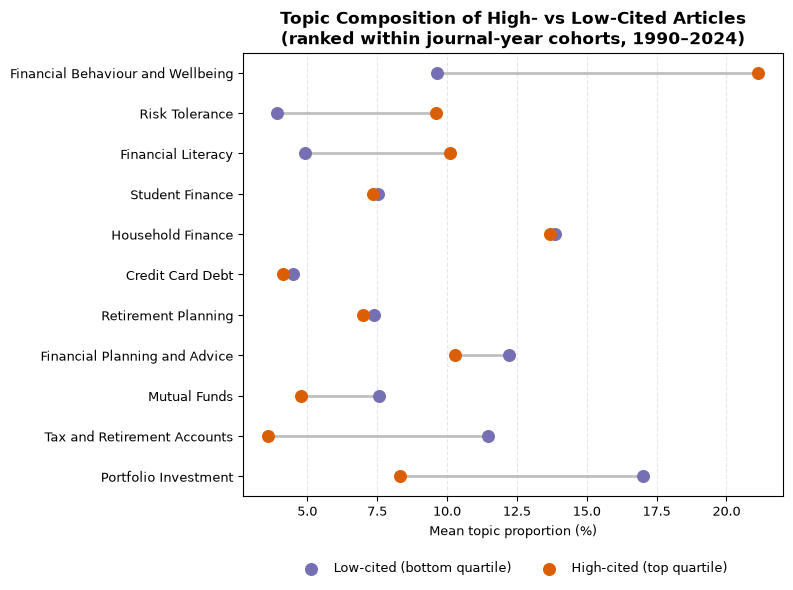

In [27]:
fig, ax = plt.subplots(figsize=(8, 6))

y_pos = np.arange(len(comparison))
low_vals = comparison["Low-cited"].values * 100
high_vals = comparison["High-cited"].values * 100

# Connecting lines
for i in range(len(comparison)):
    ax.plot([low_vals[i], high_vals[i]], [y_pos[i], y_pos[i]],
            color="grey", linewidth=2, zorder=1, alpha=0.5)

ax.scatter(low_vals, y_pos, color="#7570b3", s=70, zorder=2, label="Low-cited (bottom quartile)")
ax.scatter(high_vals, y_pos, color="#d95f02", s=70, zorder=2, label="High-cited (top quartile)")

ax.set_yticks(y_pos)
ax.set_yticklabels(comparison["topic"])
ax.invert_yaxis()
ax.set_xlabel("Mean topic proportion (%)")
ax.set_title(
    f"Topic Composition of High- vs Low-Cited Articles\n"
    f"(ranked within journal-year cohorts, {int(cohort_df['year'].min())}–{LAST_COMPLETE_YEAR - 1})",
    fontweight="bold",
)

ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("high_low_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

### FSR gap analysis

In [28]:
MIN_GAP_PP = 1.0

topic_by_journal = citation_df.groupby("journal")[nmf_topic_cols].mean().T * 100
topic_by_journal.index = [topic_label(c) for c in topic_by_journal.index]

competitors = citation_df[citation_df["journal"].isin(["FPR", "JFCP"])]

gap_table = topic_by_journal.copy()

# Article-weighted competitor average (each competitor article counts once)
gap_table["Competitor avg (%)"] = (competitors[nmf_topic_cols].mean().values * 100)

gap_table["FSR gap (pp)"] = gap_table["FSR"] - gap_table["Competitor avg (%)"]

# citation effect relative to the average topic, so it does not depend on the reference category
gap_table = gap_table.join(
    rel_df.set_index("topic")[["rel_IRR_10pp", "p_adj", "above_average"]]
)

# Opportunity: cited above the average topic AND under-represented in FSR
gap_table["Opportunity"] = (gap_table["above_average"] & (gap_table["FSR gap (pp)"] < -MIN_GAP_PP))

gap_table_display = gap_table[
    ["FSR", "FPR", "JFCP", "Competitor avg (%)", "FSR gap (pp)",
     "rel_IRR_10pp", "p_adj", "Opportunity"]
].round(3).sort_values(["Opportunity", "rel_IRR_10pp"], ascending=[False, False])

print(gap_table_display.to_string())

opportunities = gap_table_display[gap_table_display["Opportunity"]]
print(
    f"\n{len(opportunities)} under-represented, above-average-citation topic(s): "
    f"{opportunities.index.tolist()}"
)

                                      FSR     FPR    JFCP  Competitor avg (%)  FSR gap (pp)  rel_IRR_10pp  p_adj  Opportunity
Financial Literacy                  6.131   7.783   8.530               8.417        -2.286         1.190  0.000         True
Financial Behaviour and Wellbeing   5.923  11.550  27.613              25.194       -19.271         1.136  0.000         True
Student Finance                     5.221   1.722  10.911               9.527        -4.306         1.055  0.002         True
Risk Tolerance                      6.173   5.489   6.550               6.391        -0.218         1.145  0.000        False
Credit Card Debt                    3.840   1.900   4.864               4.418        -0.578         1.007  0.773        False
Household Finance                   9.238   7.971  19.079              17.406        -8.168         0.972  0.046        False
Retirement Planning                 7.885   5.457   6.576               6.408         1.477         0.950  0.008      

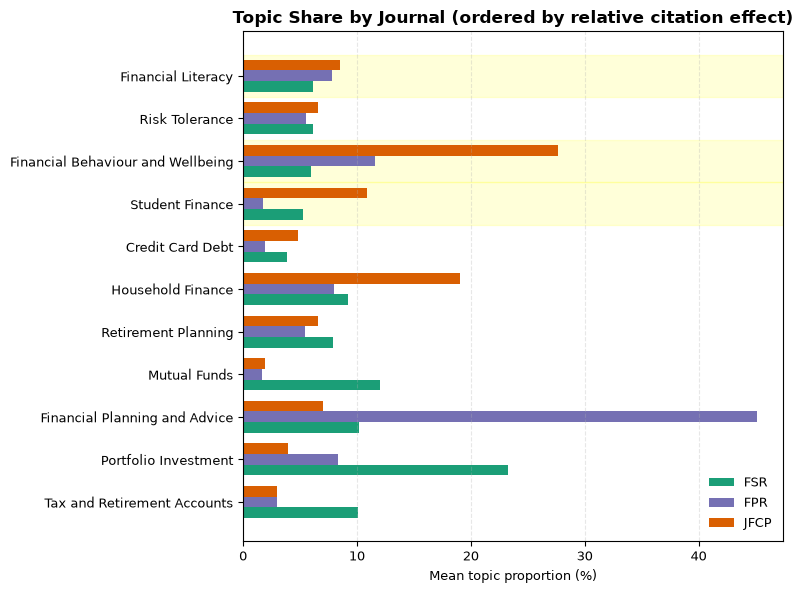

In [29]:
plot_df = gap_table_display.sort_values("rel_IRR_10pp", ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
y_pos = np.arange(len(plot_df))
bar_height = 0.25

ax.barh(y_pos - bar_height, plot_df["FSR"], height=bar_height, label="FSR", color="#1b9e77")
ax.barh(y_pos, plot_df["FPR"], height=bar_height, label="FPR", color="#7570b3")
ax.barh(y_pos + bar_height, plot_df["JFCP"], height=bar_height, label="JFCP", color="#d95f02")

# Shade the rows of topics flagged as opportunities
for i, is_opp in enumerate(plot_df["Opportunity"]):
    if is_opp:
        ax.axhspan(i - 0.5, i + 0.5, color="yellow", alpha=0.15, zorder=0)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index)
ax.set_xlabel("Mean topic proportion (%)")
ax.set_title("Topic Share by Journal (ordered by relative citation effect)", fontweight="bold")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.savefig("fsr_opportunity_chart.png", dpi=300, bbox_inches="tight")
plt.show()

### Topic trends

In [30]:
trend_base = citation_df[
    (citation_df["year"] <= LAST_COMPLETE_YEAR)
].dropna(subset=nmf_topic_cols)


def fit_trend(window_years, end_year=LAST_COMPLETE_YEAR):
    """Estimate each topic's yearly change in share over a time window."""
    start_year = end_year - window_years + 1
    d = trend_base[trend_base["year"].between(start_year, end_year)]

    results = []
    for col in nmf_topic_cols:
        d_model = d.assign(share_pp=d[col] * 100)

        # Article-level OLS: year slope with journal fixed effects
        # (separate baseline per journal), HC3 robust standard errors
        fit = smf.ols("share_pp ~ year + C(journal)", data=d_model).fit(cov_type="HC3")
        results.append({
            "topic": topic_label(col),
            "col": col,
            "slope_per_year_pp": fit.params["year"],
            "p_value": fit.pvalues["year"],
            "n_articles": int(fit.nobs),
        })

    results_df = pd.DataFrame(results)

    # Benjamini-Hochberg FDR correction across the 11 topic tests
    results_df["p_adj"] = multipletests(results_df["p_value"], method="fdr_bh")[1]
    results_df["significant"] = results_df["p_adj"] < 0.05
    return results_df.sort_values("slope_per_year_pp", ascending=False)


trend_5yr = fit_trend(5)
trend_10yr = fit_trend(10)

for name, df in [("5-year", trend_5yr), ("10-year", trend_10yr)]:
    print(f"\n{name} trend (article level, journal fixed effects):")
    print(
        df.assign(
            slope_per_year_pp=df["slope_per_year_pp"].round(3),
            p=df["p_value"].map(fmt_p),
            p_adj_fmt=df["p_adj"].map(fmt_p),
        )[["topic", "slope_per_year_pp", "p", "p_adj_fmt", "significant", "n_articles"]]
        .to_string(index=False)
    )

trend_5yr.to_csv("trend_5yr.csv", index=False)
trend_10yr.to_csv("trend_10yr.csv", index=False)


5-year trend (article level, journal fixed effects):
                            topic  slope_per_year_pp     p p_adj_fmt  significant  n_articles
Financial Behaviour and Wellbeing              2.233 0.029     0.320        False         327
                  Student Finance              0.849 0.205     0.322        False         327
             Portfolio Investment              0.792 0.120     0.322        False         327
    Financial Planning and Advice              0.684 0.360     0.440        False         327
                     Mutual Funds             -0.044 0.805     0.805        False         327
      Tax and Retirement Accounts             -0.178 0.405     0.446        False         327
              Retirement Planning             -0.533 0.269     0.370        False         327
                 Credit Card Debt             -0.736 0.098     0.322        False         327
                   Risk Tolerance             -0.858 0.155     0.322        False         327
      

In [31]:
# Sensitivity: refit the 10-year window without the latest complete year
trend_excl_latest = fit_trend(9, end_year=LAST_COMPLETE_YEAR - 1).set_index("topic")

sensitivity = trend_10yr[trend_10yr["significant"]].set_index("topic")[["slope_per_year_pp"]]
sensitivity["slope_excl_latest"] = trend_excl_latest["slope_per_year_pp"]
sensitivity["same_direction"] = (
    np.sign(sensitivity["slope_per_year_pp"]) == np.sign(sensitivity["slope_excl_latest"])
)

print(sensitivity.round(3))

                                   slope_per_year_pp  slope_excl_latest  \
topic                                                                     
Financial Behaviour and Wellbeing              2.016              1.829   
Mutual Funds                                  -0.452             -0.425   
Tax and Retirement Accounts                   -0.579             -0.508   
Portfolio Investment                          -0.615             -0.923   
Household Finance                             -0.649             -0.504   

                                   same_direction  
topic                                              
Financial Behaviour and Wellbeing            True  
Mutual Funds                                 True  
Tax and Retirement Accounts                  True  
Portfolio Investment                         True  
Household Finance                            True  


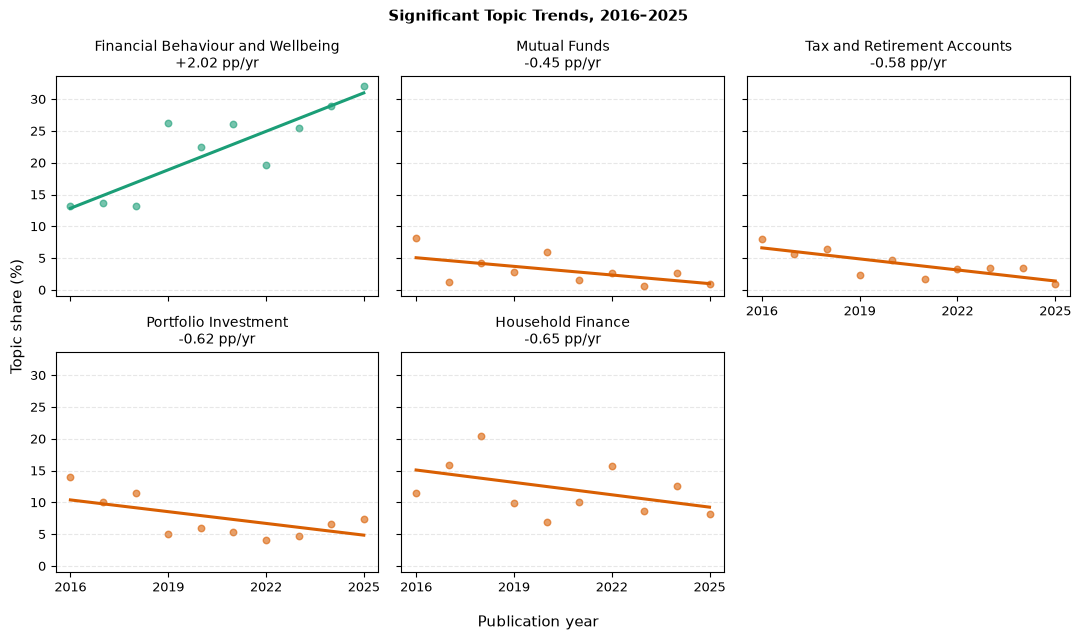

In [32]:
TREND_WINDOW = 10
start_year = LAST_COMPLETE_YEAR - TREND_WINDOW + 1
d_window = trend_base[trend_base["year"].between(start_year, LAST_COMPLETE_YEAR)]
years = np.arange(start_year, LAST_COMPLETE_YEAR + 1)


def adjusted_by_year(formula, data):
    """Mean predicted share for each year, holding every article's journal fixed."""
    fit = smf.ols(formula, data=data).fit()
    return np.array([fit.predict(data.assign(year=yr)).mean() for yr in years])


# Significant topics, rising first
sig = trend_10yr[trend_10yr["significant"]].sort_values("slope_per_year_pp", ascending=False)
n_panels = len(sig)
ncols = 3
nrows = int(np.ceil(n_panels / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(11, 3.2 * nrows), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()

for ax, (_, row) in zip(axes, sig.iterrows()):
    d_model = d_window.assign(share_pp=d_window[row["col"]] * 100)
    adj_points = adjusted_by_year("share_pp ~ C(year) + C(journal)", d_model)
    adj_line = adjusted_by_year("share_pp ~ year + C(journal)", d_model)

    colour = "#1b9e77" if row["slope_per_year_pp"] > 0 else "#d95f02"
    ax.scatter(years, adj_points, color=colour, s=22, alpha=0.6)
    ax.plot(years, adj_line, color=colour, linewidth=2.2)

    ax.set_title(f"{row['topic']}\n{row['slope_per_year_pp']:+.2f} pp/yr", fontsize=10)
    ax.set_xticks([2016, 2019, 2022, 2025])
    ax.grid(axis="y", linestyle="--", alpha=0.3)

for idx in range(n_panels, nrows * ncols):
    axes[idx].set_visible(False)
    axes[idx - ncols].tick_params(labelbottom=True)

fig.suptitle(f"Significant Topic Trends, {start_year}–{LAST_COMPLETE_YEAR}", fontweight="bold")
fig.supxlabel("Publication year")
fig.supylabel("Topic share (%)")

plt.tight_layout()
plt.savefig("topic_trends_10yr.png", dpi=300, bbox_inches="tight")
plt.show()